In [1]:

# Level 3: Business Intelligence Analytics System

import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

from google.colab import files

uploaded = files.upload()


Saving SampleSuperstore.csv to SampleSuperstore.csv


In [4]:

# Step 5: Load and inspect the sales dataset

df = pd.read_csv("SampleSuperstore.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Number of rows and columns: (9994, 13)

Column names:
['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']

First 5 rows:


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164



Missing values:
Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64


In [5]:

# Step 6: Create a SQLite database and load sales data

import sqlite3

# Create the database file
conn = sqlite3.connect("Business_Intelligence.db")

# Load the DataFrame into a SQL table
df.to_sql("sales", conn, if_exists="replace", index=False)

print("SQL database created successfully!")
print("Table 'sales' created successfully!")


SQL database created successfully!
Table 'sales' created successfully!


In [6]:

# Step 7: Run our first SQL query

query = """
SELECT
    COUNT(*) AS total_orders,
    ROUND(SUM(Sales), 2) AS total_sales,
    ROUND(SUM(Profit), 2) AS total_profit,
    SUM(Quantity) AS total_quantity
FROM sales;
"""

result = pd.read_sql_query(query, conn)
display(result)


,total_orders,total_sales,total_profit,total_quantity
0,9994,2297200.86,286397.02,37873


In [7]:

# Step 8A: Sales by Region

query_region = """
SELECT
    Region,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit
FROM sales
GROUP BY Region
ORDER BY Total_Sales DESC;
"""

display(pd.read_sql_query(query_region, conn))


,Region,Total_Sales,Total_Profit
0,West,725457.82,108418.45
1,East,678781.24,91522.78
2,Central,501239.89,39706.36
3,South,391721.91,46749.43


In [8]:

# Step 8B: Sales by Category

query_category = """
SELECT
    Category,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    SUM(Quantity) AS Total_Quantity
FROM sales
GROUP BY Category
ORDER BY Total_Sales DESC;
"""

display(pd.read_sql_query(query_category, conn))


,Category,Total_Sales,Total_Profit,Total_Quantity
0,Technology,836154.03,145454.95,6939
1,Furniture,741999.80,18451.27,8028
2,Office Supplies,719047.03,122490.80,22906


In [9]:

# Step 10: Profit by Sub-Category

query_subcategory = """
SELECT
    "Sub-Category",
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit
FROM sales
GROUP BY "Sub-Category"
ORDER BY Total_Profit DESC;
"""

display(pd.read_sql_query(query_subcategory, conn))


,Sub-Category,Total_Sales,Total_Profit
0,Copiers,149528.03,55617.82
1,Phones,330007.05,44515.73
2,Accessories,167380.32,41936.64
3,Paper,78479.21,34053.57
4,Binders,203412.73,30221.76
5,Chairs,328449.10,26590.17
6,Storage,223843.61,21278.83
7,Appliances,107532.16,18138.01
8,Furnishings,91705.16,13059.14
9,Envelopes,16476.40,6964.18


In [10]:

# Step 12: ETL Pipeline

# EXTRACT
etl_df = pd.read_csv("SampleSuperstore.csv")
print("Extracted rows:", len(etl_df))

# TRANSFORM
etl_df.columns = etl_df.columns.str.strip()

rows_before = len(etl_df)
etl_df = etl_df.drop_duplicates()
duplicates_removed = rows_before - len(etl_df)

for col in ["Sales", "Quantity", "Discount", "Profit"]:
    etl_df[col] = pd.to_numeric(etl_df[col], errors="coerce")

etl_df = etl_df.dropna(
    subset=["Sales", "Quantity", "Discount", "Profit"]
)

print("Duplicates removed:", duplicates_removed)
print("Rows after cleaning:", len(etl_df))

# LOAD
etl_df.to_sql(
    "sales_cleaned",
    conn,
    if_exists="replace",
    index=False
)

print("ETL pipeline completed successfully!")


Extracted rows: 9994
Duplicates removed: 17
Rows after cleaning: 9977
ETL pipeline completed successfully!


In [11]:

# Step 13: Verify the cleaned SQL table

verification_query = """
SELECT
    COUNT(*) AS total_rows,
    ROUND(SUM(Sales), 2) AS total_sales,
    ROUND(SUM(Profit), 2) AS total_profit,
    SUM(Quantity) AS total_quantity
FROM sales_cleaned;
"""

verification_result = pd.read_sql_query(
    verification_query, conn
)

display(verification_result)


,total_rows,total_sales,total_profit,total_quantity
0,9977,2296195.59,286241.42,37820


In [12]:

# Step 14: Save the database file

conn.commit()
conn.close()

print("SQL database saved successfully!")


SQL database saved successfully!


In [13]:

from google.colab import files

files.download("Business_Intelligence.db")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("SampleSuperstore.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)


Dataset loaded successfully!
Rows and columns: (9994, 13)


In [15]:

# Step 16: Prepare monthly sales data for forecasting

df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df = df.dropna(subset=["Order Date", "Sales"])

monthly_sales = (
    df.set_index("Order Date")["Sales"]
      .resample("MS")
      .sum()
      .reset_index()
)

monthly_sales.columns = ["Month", "Sales"]

print("Monthly sales data prepared!")
print("Number of months:", len(monthly_sales))

display(monthly_sales.head())


KeyError: 'Order Date'

In [16]:

# Check the exact column names in your dataset

print(df.columns.tolist())


['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']


In [19]:

from google.colab import files

uploaded = files.upload()


Saving Sample_Superstore.csv to Sample_Superstore.csv


In [22]:
import pandas as pd

forecast_df = pd.read_csv("Superstore_With_Dates.csv")

print("Dataset shape:", forecast_df.shape)
print("Available columns:")
print(forecast_df.columns.tolist())

FileNotFoundError: [Errno 2] No such file or directory: 'Superstore_With_Dates.csv'

In [23]:
import os

print(os.listdir("/content"))

['.config', '8bd642f6c46792a9c40c8ccad60391e9-4fd45d58a0a81c69814d270d7658f5e2a2d81154 (1).zip', 'SampleSuperstore.csv', 'Business_Intelligence_Analytics_System.pbix', '8bd642f6c46792a9c40c8ccad60391e9-4fd45d58a0a81c69814d270d7658f5e2a2d81154.zip', 'Sample_Superstore.csv', 'Business_Intelligence.db', 'sample_data']


In [24]:
import pandas as pd

forecast_df = pd.read_csv("Sample_Superstore.csv")

print("Dataset shape:", forecast_df.shape)
print("Columns:", forecast_df.columns.tolist())

Dataset shape: (9994, 21)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [25]:
forecast_df["Order Date"] = pd.to_datetime(
    forecast_df["Order Date"], errors="coerce"
)

print("Earliest order:", forecast_df["Order Date"].min())
print("Latest order:", forecast_df["Order Date"].max())
print("Invalid dates:", forecast_df["Order Date"].isna().sum())

Earliest order: 2014-01-02 00:00:00
Latest order: 2017-12-30 00:00:00
Invalid dates: 0


/tmp/ipykernel_814/3073131671.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  forecast_df["Order Date"] = pd.to_datetime(


In [26]:
# Make a copy so the original data remains unchanged
forecast_df["Order Date"] = pd.to_datetime(
    forecast_df["Order Date"], format="mixed"
)

# Aggregate sales by month
monthly_sales = (
    forecast_df
    .set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Month", "Sales"]

print("Number of months:", len(monthly_sales))
print(monthly_sales.head())
print(monthly_sales.tail())

Number of months: 48
       Month      Sales
0 2014-01-01  28953.706
1 2014-02-01  12743.108
2 2014-03-01  54801.906
3 2014-04-01  24710.016
4 2014-05-01  29639.834
        Month       Sales
43 2017-08-01  75675.3040
44 2017-09-01  74164.6080
45 2017-10-01  65501.1622
46 2017-11-01  89306.2400
47 2017-12-01  56969.1958


Training months: 36
Testing months: 12
MAE: 13764.75
RMSE: 15995.80


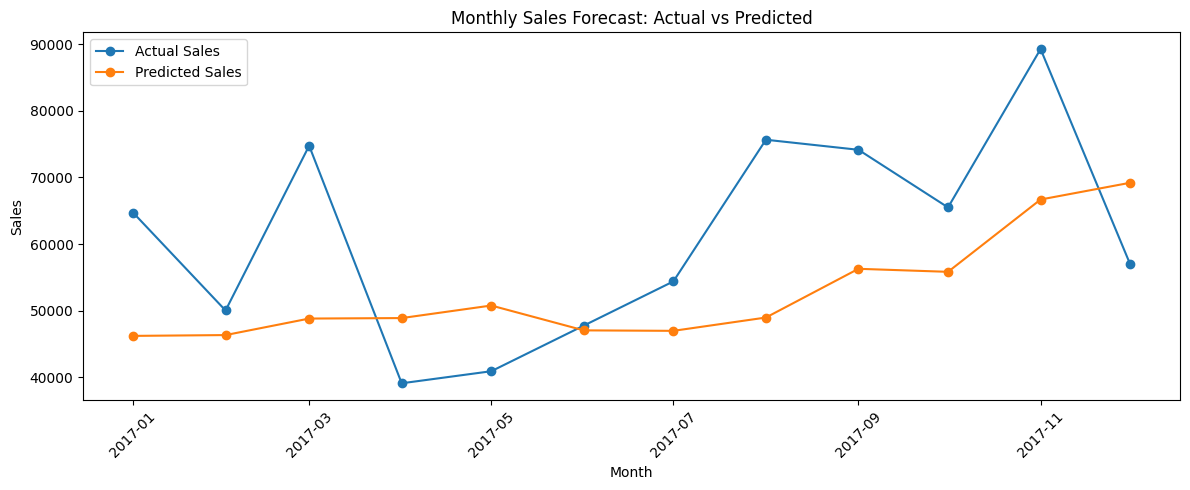

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create time-based features
data = monthly_sales.copy()
data["Month"] = pd.to_datetime(data["Month"])
data["Month_Number"] = np.arange(len(data))
data["Calendar_Month"] = data["Month"].dt.month

# Use the first 36 months for training
train = data.iloc[:36]
test = data.iloc[36:]

features = ["Month_Number", "Calendar_Month"]

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

model.fit(train[features], train["Sales"])

# Predict the final 12 months
test_predictions = model.predict(test[features])

# Evaluate the model
mae = mean_absolute_error(test["Sales"], test_predictions)
rmse = np.sqrt(mean_squared_error(test["Sales"], test_predictions))

print("Training months:", len(train))
print("Testing months:", len(test))
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

# Plot actual vs predicted sales
plt.figure(figsize=(12, 5))
plt.plot(test["Month"], test["Sales"], marker="o", label="Actual Sales")
plt.plot(test["Month"], test_predictions, marker="o", label="Predicted Sales")
plt.title("Monthly Sales Forecast: Actual vs Predicted")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Seasonal baseline: use sales from 12 months earlier
actual = data["Sales"].iloc[36:].to_numpy()
seasonal_predictions = data["Sales"].iloc[24:36].to_numpy()

rf_mae = mean_absolute_error(actual, test_predictions)
rf_rmse = np.sqrt(mean_squared_error(actual, test_predictions))

seasonal_mae = mean_absolute_error(actual, seasonal_predictions)
seasonal_rmse = np.sqrt(mean_squared_error(actual, seasonal_predictions))

print("Model comparison on the same 12 test months")
print(f"Random Forest MAE: {rf_mae:.2f}")
print(f"Random Forest RMSE: {rf_rmse:.2f}")
print(f"Seasonal baseline MAE: {seasonal_mae:.2f}")
print(f"Seasonal baseline RMSE: {seasonal_rmse:.2f}")

Model comparison on the same 12 test months
Random Forest MAE: 13764.75
Random Forest RMSE: 15995.80
Seasonal baseline MAE: 18031.99
Seasonal baseline RMSE: 20424.97


     Month  Month_Number  Calendar_Month  Forecast_Sales
2018-01-01            48               1        46194.26
2018-02-01            49               2        46316.33
2018-03-01            50               3        48798.86
2018-04-01            51               4        48871.63
2018-05-01            52               5        50758.48
2018-06-01            53               6        47024.12
2018-07-01            54               7        46952.75
2018-08-01            55               8        48952.51
2018-09-01            56               9        56276.60
2018-10-01            57              10        55822.77
2018-11-01            58              11        66690.59
2018-12-01            59              12        69207.67


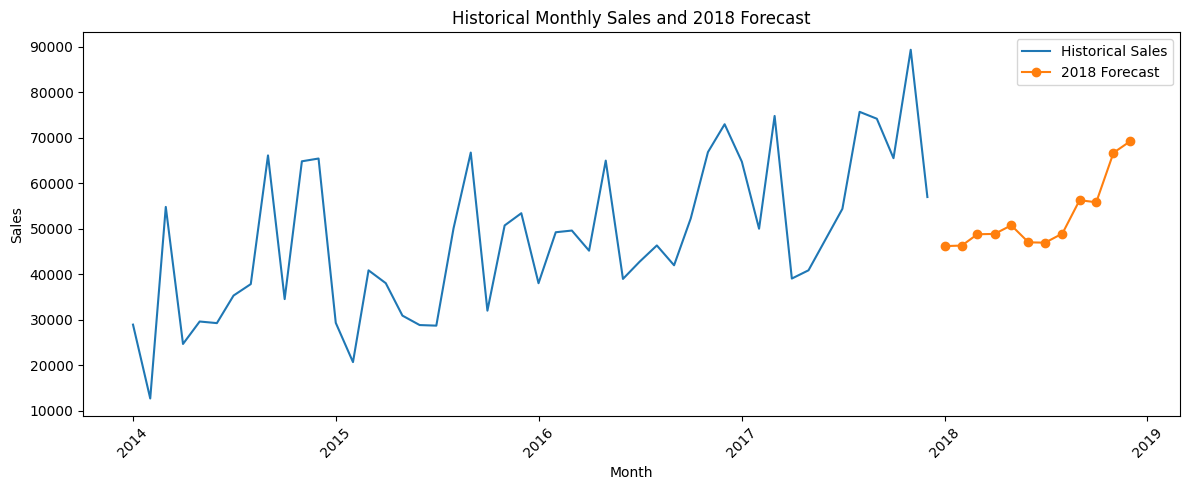

In [29]:
# Create the next 12 months
future_dates = pd.date_range(
    start="2018-01-01",
    periods=12,
    freq="MS"
)

future_df = pd.DataFrame({
    "Month": future_dates
})

# Create the same features used during training
future_df["Month_Number"] = np.arange(
    len(data), len(data) + 12
)
future_df["Calendar_Month"] = future_df["Month"].dt.month

# Predict future sales
future_df["Forecast_Sales"] = model.predict(
    future_df[["Month_Number", "Calendar_Month"]]
)

print(future_df.round(2).to_string(index=False))

# Save the forecast as a CSV file
future_df.to_csv("Monthly_Sales_Forecast_2018.csv", index=False)

# Plot historical and forecast sales
plt.figure(figsize=(12, 5))
plt.plot(data["Month"], data["Sales"], label="Historical Sales")
plt.plot(
    future_df["Month"],
    future_df["Forecast_Sales"],
    marker="o",
    label="2018 Forecast"
)
plt.title("Historical Monthly Sales and 2018 Forecast")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

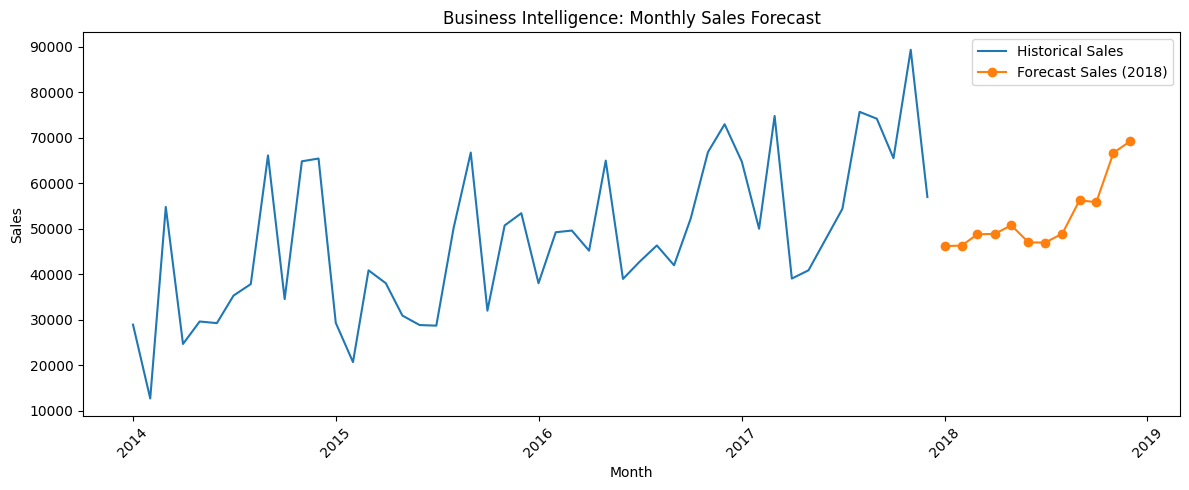

Forecast CSV and graph saved successfully.


In [30]:
from google.colab import files
import matplotlib.pyplot as plt

# Save forecast results
future_df.to_csv("Monthly_Sales_Forecast_2018.csv", index=False)

# Save forecast graph
plt.figure(figsize=(12, 5))
plt.plot(data["Month"], data["Sales"], label="Historical Sales")
plt.plot(
    future_df["Month"],
    future_df["Forecast_Sales"],
    marker="o",
    label="Forecast Sales (2018)"
)
plt.title("Business Intelligence: Monthly Sales Forecast")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("Monthly_Sales_Forecast.png", dpi=300, bbox_inches="tight")
plt.show()

print("Forecast CSV and graph saved successfully.")

In [31]:
files.download("Monthly_Sales_Forecast_2018.csv")
files.download("Monthly_Sales_Forecast.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>